# НПВ при строительстве скважин Volve: классификация, повторяемость, план

Расчёты к [README](../README.md). Порядок тот же: баланс времени, виды и причины НПВ, динамика,
повторяемость отказов, план НПВ на скважину и карта рисков, затем отдельно разведка.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd

from volve import analysis as A
from volve import figures as F
from volve import npt, viz

viz.setup()
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.max_colwidth", 140)

reports, ops = A.prepare()
ev = npt.events(ops)
dev = ops[ops.scope == A.DEVELOPMENT]
expl = ops[ops.scope == A.EXPLORATION]
print(f"рапортов {len(reports):,}, операций {len(ops):,}, стволов {ops.wellbore.nunique()}, суток станка {ops.hours.sum() / 24:,.0f}")

рапортов 1,758, операций 23,447, стволов 26, суток станка 1,641


## 1. Объект: одна площадь, три станка, два разных вида работ

Разведочные стволы 15/9-19 бурили с двух ППБУ в 1992–1998 годах. Эксплуатационные стволы 15/9-F бурила одна СПБУ
в 2007–2016 годах. Дальше они считаются раздельно.

стволов              начало  \
scope                    rig_ru                                                
разведочное бурение      ППБУ Byford Dolphin           4 1997-07-16 15:30:00   
                         ППБУ Treasure Prospect        2 1992-09-08 18:00:00   
эксплуатационное бурение СПБУ Mærsk Inspirer          21 2007-06-09 12:00:00   

                                                              конец   суток  
scope                    rig_ru                                              
разведочное бурение      ППБУ Byford Dolphin    1998-02-04 06:00:00   202.6  
                         ППБУ Treasure Prospect 1993-04-29 09:00:00   161.3  
эксплуатационное бурение СПБУ Mærsk Inspirer    2016-10-24 00:00:00 1,277.6

,сутки,"ПВ, ч","НПВ, ч","метео, ч","НПВ, %","метео, %","НПВ, ч/сут"
program,,,,,,,
КРС 2008–2016,105.9,"2,164.6",317.7,59.0,12.5,2.3,3.0
бурение 2007–2009,643.7,"12,265.5","2,626.5",556.8,17.0,3.6,4.1
бурение 2013–2014,399.4,"7,451.2","1,356.2",779.0,14.1,8.1,3.4
ликвидация 2016,128.6,"2,488.2",511.6,85.8,16.6,2.8,4.0
разведка 1992–1998,363.9,"5,400.0","2,889.0",444.0,33.1,5.1,7.9


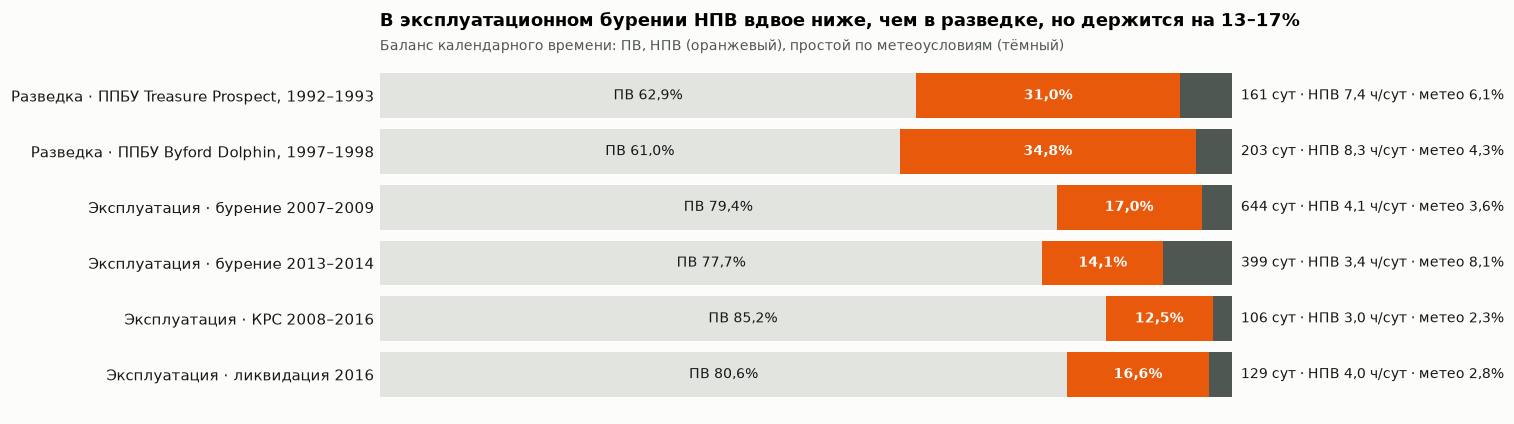

In [2]:
display(ops.groupby(["scope", "rig_ru"]).agg(стволов=("wellbore", "nunique"), начало=("t_start", "min"), конец=("t_end", "max"),
                                             суток=("hours", lambda s: s.sum() / 24)))
display(A.balance(ops, "program"))
F.balance(ops); plt.show()

## 2. Учёт НПВ в рапортах и его проверка

НПВ — операции группы `interruption` (кроме метео), операции с отметкой `fail` и операции с отметкой
`stateDetailActivity`, отличной от `success`. Последние записаны под плановыми кодами (спуск колонны, СПО),
но это работы после отказа: подъём хвостовика труболовкой, повторный спуск, смена телесистемы.

In [3]:
n = ops[ops.time_class == "npt"]
hidden = n[~((n.activity_group == "interruption") | (n.state == "fail"))]
print(f"НПВ всего {n.hours.sum():,.0f} ч, из них под плановыми кодами {hidden.hours.sum():,.0f} ч ({hidden.hours.sum() / n.hours.sum():.0%})")
print(f"код interruption/other: {n[(n.activity_group == 'interruption') & (n.activity == 'other')].hours.sum() / n.hours.sum():.0%} НПВ")
display((n.groupby("npt_source").hours.sum() / n.hours.sum() * 100).sort_values(ascending=False).to_frame("% НПВ"))
vague = n[n.npt_cause.isin(["узел не указан", "повторные работы без описания", "ожидание прочее", npt.UNKNOWN])]
print(f"без конкретной причины осталось {vague.hours.sum():,.0f} ч ({vague.hours.sum() / n.hours.sum():.1%} НПВ)")

НПВ всего 7,701 ч, из них под плановыми кодами 1,063 ч (14%)
код interruption/other: 35% НПВ


,% НПВ
npt_source,
комментарий,51.4
соседняя операция события,23.3
код операции,18.7
отметка рапорта,6.5
нет,0.0


без конкретной причины осталось 178 ч (2.3% НПВ)


In [4]:
# Выборочная проверка разметки: 30 операций, вероятность выбора пропорциональна часам
check = n.sample(30, weights=n.hours, random_state=3)[["wellbore", "hours", "npt_kind", "npt_cause", "npt_source", "comment"]]
check.assign(comment=check.comment.str.replace("\n", " ").str[:130])

,wellbore,hours,npt_kind,npt_cause,npt_source,comment
5473,15/9-F-11 T2,0.5,ремонт бурового оборудования,насосы и циркуляционная система,соседняя операция события,"R/U wireline, RIH and took Gyro survey (345 m bit depth): Survey station (m) Inclination (deg) Azi (deg) 305"
8475,15/9-F-14,5.5,ремонт бурового оборудования,верхний привод,комментарий,Parked TDS for service. Worked on TDS allignment cylinder. Meanwhile pressure tested valves in kill and choke manifolds to 35/345
1519,15/9-19 ST2,6.0,авария,перебуривание ствола,код операции,CONTINUED RIH FROM 37M TO 2207M. BROKE CIRCULATION EVERY 500M.
4225,15/9-F-11 A,3.5,ремонт бурового оборудования,верхний привод,комментарий,Isolated TDS hydraulically. Repaired leaking hydraulic pipe fitting and installed overhauled hydraulic cooler.
19218,15/9-F-4,3.5,авария,ловильные работы,соседняя операция события,"RIH with spear assembly on 5 1/2"" DP from 693 m to 2466 m MD. Meanwhile changed out csg tong on fwd iron roughneck."
19227,15/9-F-4,8.8,авария,ловильные работы,комментарий,"POOH with 7"" liner on spear assembly from 2716 m to 867 m MD. Spaced out inside BOP. Flow checked for 15 min on last joint of 5"
531,15/9-19 A,6.5,отказ оборудования сервисов,ГИС и канатная техника,комментарий,RIH WITH MWS BOTTOM HOLE SAMPLING TOOL. SAMPLE CHAMBER FAILED TO OPEN. POOH WITH WIRELINE.
1024,15/9-19 BT2,3.0,ремонт бурового оборудования,"энергетика, гидравлика, системы управления",комментарий,ATLAS PULLED WET CONNECTOR LOOSE - REQUIRED 65 MINUTES OF CONSTANT PULLING & WORKING ELECTRIC LINE & RECIPROCATING DRILLPIPE. FINA
365,15/9-19 A,18.0,простой,забастовка,комментарий,OPERATIONS SUSPENDED DUE TO OFS STRIKE.
18295,15/9-F-1 C,5.0,простой,"ожидание материалов, персонала, судна",соседняя операция события,"Worked on preparing WL cutting equipment, hooked up logging container. Meanwhile prepared flat bottom milling assembly for the dre"


## 3. Эксплуатационное бурение: виды и причины НПВ

,часы,% НПВ,% календарного времени
npt_kind,,,
ремонт бурового оборудования,"2,549.3",53.0,8.3
простой,669.3,13.9,2.2
отказ оборудования сервисов,600.9,12.5,2.0
авария,442.8,9.2,1.4
брак,219.5,4.6,0.7
осложнение,213.9,4.4,0.7
инцидент,115.0,2.4,0.4
причина не указана,1.2,0.0,0.0


program,КРС 2008–2016,бурение 2007–2009,бурение 2013–2014,ликвидация 2016
npt_kind,,,,
ремонт бурового оборудования,3.7,9.8,7.8,6.3
отказ оборудования сервисов,2.7,1.7,2.0,2.2
осложнение,0.2,0.8,0.4,1.7
авария,0.0,1.9,1.0,1.7
брак,0.0,1.4,0.0,0.0
простой,5.8,0.9,2.5,4.5
инцидент,0.0,0.5,0.4,0.1
причина не указана,0.0,0.0,0.0,0.0


доля НПВ и 95% интервал: [np.float64(15.7), np.float64(14.3), np.float64(17.1)]


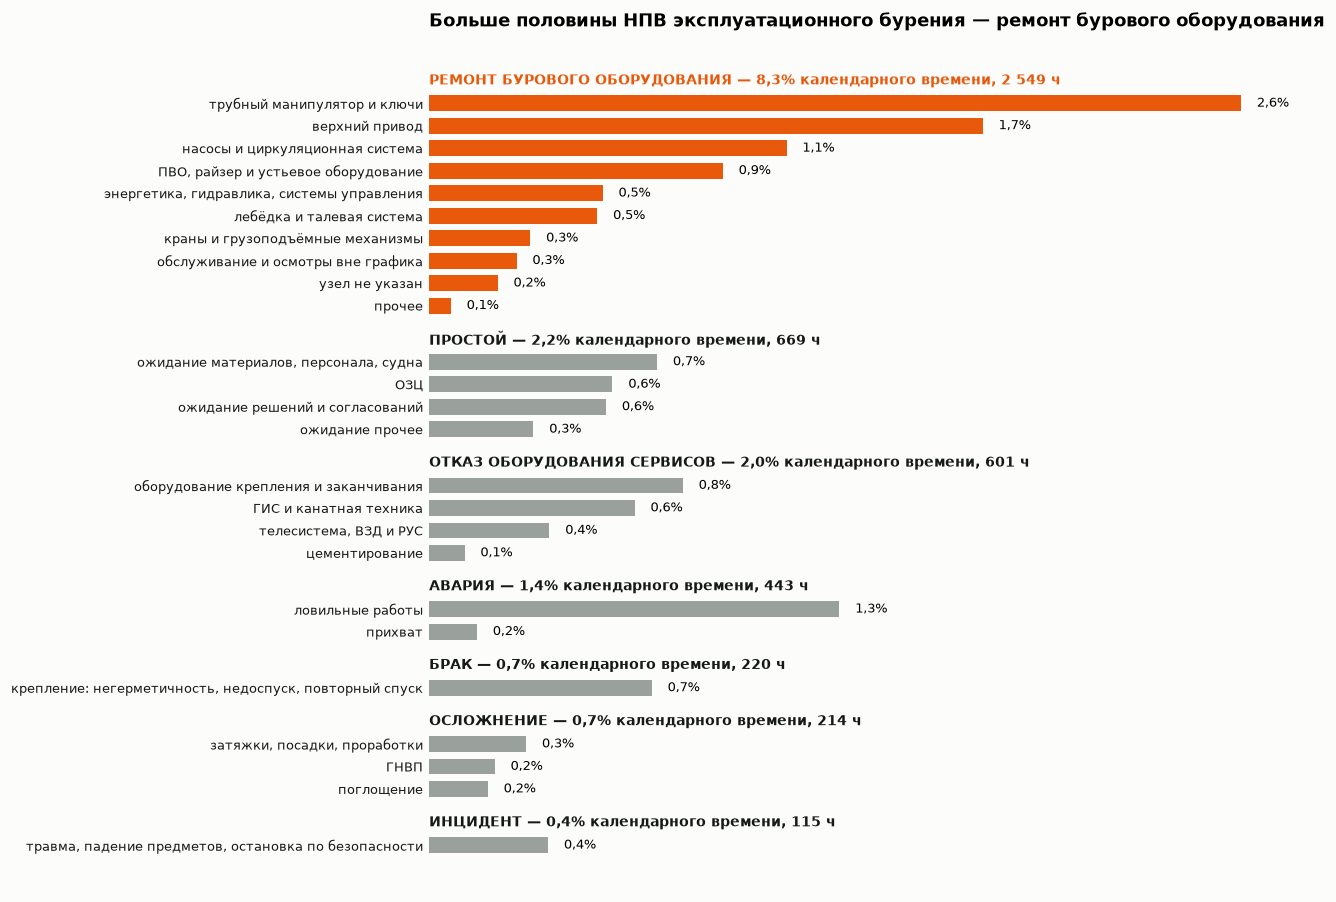

In [5]:
k = dev[dev.time_class == "npt"].groupby("npt_kind").hours.sum().sort_values(ascending=False)
display(pd.DataFrame({"часы": k, "% НПВ": k / k.sum() * 100, "% календарного времени": k / dev.hours.sum() * 100}))
display((A.kinds(dev, "program").T / dev.groupby("program").hours.sum() * 100).round(1))
print("доля НПВ и 95% интервал:", [round(v, 1) for v in A.share_ci(dev)])
F.structure(dev, "Больше половины НПВ эксплуатационного бурения — ремонт бурового оборудования"); plt.show()

In [6]:
# Крупнейшие события НПВ эксплуатационного бурения
de = ev[ev.scope == A.DEVELOPMENT]
print(f"событий {len(de)}, медиана {de.hours.median():.2f} ч, дольше суток {(de.hours >= 24).sum()} — {de[de.hours >= 24].hours.sum() / de.hours.sum():.0%} НПВ")
top = de.sort_values("hours", ascending=False).head(15)
top.assign(comment=top.comment.str.replace("\n", " ").str[:120])[["wellbore", "start", "hours", "npt_kind", "npt_cause", "comment"]]

событий 837, медиана 1.75 ч, дольше суток 39 — 43% НПВ


,wellbore,start,hours,npt_kind,npt_cause,comment
847,15/9-F-4,2008-03-02 22:15:00,142.2,авария,ловильные работы,"RIH with 7"" liner from 963 m to 3392 m MD, filling every 5th stds. Broke circulation at shoe at 2756 m for 5 min, 500 lp"
507,15/9-F-12,2008-01-05 14:00:00,139.0,ремонт бурового оборудования,трубный манипулятор и ключи,Waited for weather condtions to improve for resuming AFT PRS repair work. Meanwhile : -Removed lead target in cement un
348,15/9-F-11,2013-03-18 00:00:00,125.5,ремонт бурового оборудования,верхний привод,Waited on cement. Meanwhile: changed encoder on aft PRS. Performed maintenance on top drive and trouble shoot alignment
399,15/9-F-11 T2,2013-03-24 17:30:00,105.2,ремонт бурового оборудования,лебёдка и талевая система,Prepared for changing out fast-line sheave in crown block. Transferred high-torque tools to derrick. Loosened all bolts
839,15/9-F-4,2008-02-19 02:30:00,88.5,авария,ловильные работы,"Ran 5 1/2"" DP singles over 7/48 wireline from 268 m to 780 m MD according to cut and thread procedure. Laid out singles"
514,15/9-F-12,2008-01-19 06:00:00,82.0,брак,"крепление: негерметичность, недоспуск, повторный спуск",Waited for tubing puncher equipment and schlumberger personnel to arrive on the rig. Meanwhile: -Performed derrick insp
342,15/9-F-11,2013-03-09 02:45:00,79.2,авария,ловильные работы,Evaluated situation and discussed same with town. Prepared plans for various fishing scenerios and mobilized additional
493,15/9-F-12,2007-09-05 03:30:00,75.5,отказ оборудования сервисов,оборудование крепления и заканчивания,"RIH with 9 5/8"" tie-back casing from surface to 374 m MD. Observed high thread torque on several joints.Observed some dr"
372,15/9-F-11 B,2013-07-15 01:45:00,66.5,отказ оборудования сервисов,ГИС и канатная техника,Worked assembly from 3670 m to 3921 m. Unable to pass 3921 m.
492,15/9-F-12,2007-09-02 05:00:00,65.5,отказ оборудования сервисов,оборудование крепления и заканчивания,"POOH with 10 3/4"" casing from 1670 m to 822 m MD. Average pulling speed 13 jnts/hr."


## 4. Динамика по кварталам

npt_kind,часы,"НПВ, %","метео, %"
quarter,,,
2007Q2,516.0,14.8,0.0
2007Q3,"2,207.7",19.5,1.3
2007Q4,"2,017.0",10.8,4.5
2008Q1,"2,086.0",39.0,10.9
2008Q2,"1,839.2",14.1,0.7
2008Q3,"1,904.2",16.5,0.0
2008Q4,"1,627.5",13.4,1.1
2009Q1,"1,655.8",6.8,8.8
2009Q2,"1,855.0",9.4,1.7


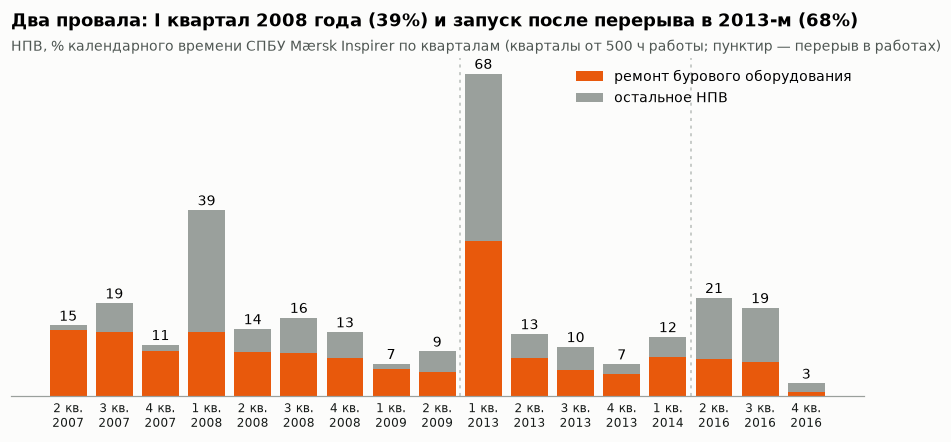

In [7]:
q = A.quarterly(dev)
display(q[q["часы"] >= 500][["часы", "НПВ, %", "метео, %"]])
F.dynamics(dev); plt.show()

## 5. Повторяемость отказов

Вопрос: видно ли по данным, что с повторяющимися отказами работали. Мерило — часы НПВ узла на 1000 часов работы станка.

,npt_kind,npt_cause,events,hours,median_h,max_h,first,last
11,ремонт бурового оборудования,трубный манипулятор и ключи,224,755.9,0.8,139.0,2007-06-10 10:30:00,2016-10-04 02:00:00
6,ремонт бурового оборудования,верхний привод,105,540.2,2.5,125.5,2007-06-10 20:30:00,2016-09-29 01:30:00
2,отказ оборудования сервисов,оборудование крепления и заканчивания,32,299.5,3.2,75.5,2007-07-19 21:15:00,2016-09-13 04:00:00
9,ремонт бурового оборудования,насосы и циркуляционная система,69,294.5,2.0,29.0,2007-06-17 05:45:00,2016-09-24 01:45:00
0,отказ оборудования сервисов,ГИС и канатная техника,24,251.8,7.6,66.5,2008-02-17 16:30:00,2016-09-20 08:15:00
5,ремонт бурового оборудования,"ПВО, райзер и устьевое оборудование",47,206.2,2.8,14.8,2007-07-01 06:00:00,2016-09-21 13:15:00
14,ремонт бурового оборудования,"энергетика, гидравлика, системы управления",37,202.0,1.2,38.0,2007-08-08 10:00:00,2016-07-09 08:30:00
8,ремонт бурового оборудования,лебёдка и талевая система,27,182.8,2.2,105.2,2007-08-25 15:15:00,2016-07-15 21:15:00
3,отказ оборудования сервисов,"телесистема, ВЗД и РУС",19,101.2,1.5,34.8,2007-08-12 07:15:00,2014-03-12 08:45:00
12,ремонт бурового оборудования,узел не указан,37,76.5,1.0,19.5,2007-07-06 16:15:00,2016-09-09 20:15:00


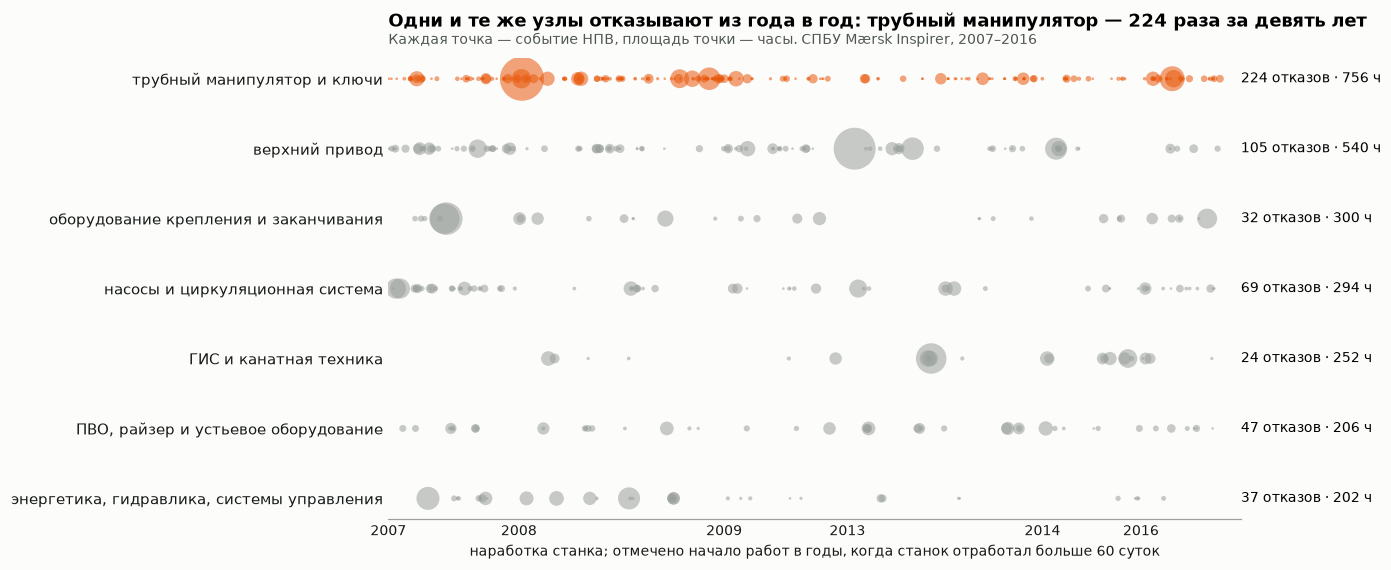

In [8]:
rep, _ = A.repeats(de[de.npt_kind.isin([npt.REPAIR, npt.SERVICE])])
display(rep[["npt_kind", "npt_cause", "events", "hours", "median_h", "max_h", "first", "last"]].head(10))
F.repeats_timeline(ops, ev); plt.show()

In [9]:
from volve.report import UNITS
periods = ["бурение 2007–2009", "бурение 2013–2014", "ликвидация 2016"]
for unit in UNITS:
    print(unit); display(A.failure_rate(dev, de, unit, periods))
F.rates(ops, ev, UNITS); plt.show()

трубный манипулятор и ключи


,часы станка,events,npt_h,отказов на 1000 ч,"НПВ, ч на 1000 ч"
program,,,,,
бурение 2007–2009,"15,448.7",144,545.8,9.3,35.3
бурение 2013–2014,"9,586.5",48,87.8,5.0,9.2
ликвидация 2016,"3,085.5",27,117.8,8.8,38.2


верхний привод


,часы станка,events,npt_h,отказов на 1000 ч,"НПВ, ч на 1000 ч"
program,,,,,
бурение 2007–2009,"15,448.7",73.0,249.5,4.7,16.2
бурение 2013–2014,"9,586.5",27.0,272.0,2.8,28.4
ликвидация 2016,"3,085.5",5.0,18.8,1.6,6.1


насосы и циркуляционная система


,часы станка,events,npt_h,отказов на 1000 ч,"НПВ, ч на 1000 ч"
program,,,,,
бурение 2007–2009,"15,448.7",45,193.2,2.9,12.5
бурение 2013–2014,"9,586.5",9,69.2,0.9,7.2
ликвидация 2016,"3,085.5",10,16.2,3.2,5.3


ПВО, райзер и устьевое оборудование


,часы станка,events,npt_h,отказов на 1000 ч,"НПВ, ч на 1000 ч"
program,,,,,
бурение 2007–2009,"15,448.7",21,86.0,1.4,5.6
бурение 2013–2014,"9,586.5",17,100.8,1.8,10.5
ликвидация 2016,"3,085.5",7,14.8,2.3,4.8


In [10]:
# Сквозная проблема: колонна-надставка (tie-back) 10 3/4"
nd = dev[dev.time_class == "npt"]
tb = nd[nd.event.isin(nd[nd.comment.str.contains("tie-?back|tieback", case=False, na=False)].event.unique())]
print(f"событий {tb.event.nunique()}, часов {tb.hours.sum():,.0f}")
tb.groupby("wellbore").agg(начало=("t_start", "min"), часов=("hours", "sum")).sort_values("начало")

событий 13, часов 442


,начало,часов
wellbore,,
15/9-F-12,2007-09-02 05:00:00,276.8
15/9-F-4,2008-04-03 08:00:00,13.0
15/9-F-5,2008-08-12 15:00:00,47.1
15/9-F-15 C,2009-02-08 03:00:00,18.8
15/9-F-1 B,2014-02-05 16:15:00,2.5
15/9-F-1 C,2014-03-31 00:00:00,55.8
15/9-F-15 D,2016-07-26 11:00:00,28.0


## 6. План НПВ на скважину и карта рисков

Проверка «как было бы»: перед каждой скважиной план считается только по скважинам, законченным раньше.

In [11]:
wells = A.wells_table(ops)
display(wells)
plan = A.npt_plan(wells)
display(plan)
F.plan(plan); plt.show()

,wellbore,start,days,md,npt_h,wow_h,npt_share,program
0,15/9-F-4,2007-06-09 12:00:00,101.6,"3,510.0",587.0,217.0,24.1,бурение 2007–2009
1,15/9-F-12,2007-06-13 20:00:00,129.9,"3,520.0",861.0,49.2,27.6,бурение 2007–2009
2,15/9-F-7,2007-09-14 21:00:00,31.2,"1,083.0",86.0,6.5,11.5,бурение 2007–2009
3,15/9-F-14,2007-11-05 11:00:00,82.6,"3,750.0",280.2,88.2,14.1,бурение 2007–2009
4,15/9-F-5,2007-11-15 04:30:00,52.0,"3,793.0",175.8,0.5,14.1,бурение 2007–2009
5,15/9-F-15,2007-11-18 23:45:00,59.8,"4,090.0",244.2,13.2,17.0,бурение 2007–2009
6,15/9-F-9,2007-11-28 06:30:00,19.0,"1,083.0",55.2,0.0,12.1,бурение 2007–2009
7,15/9-F-1,2007-12-01 04:30:00,35.1,"3,632.0",84.0,6.2,10.0,бурение 2007–2009
8,15/9-F-15 A,2008-12-11 15:00:00,32.3,"4,097.0",48.8,16.2,6.3,бурение 2007–2009
9,15/9-F-15 C,2009-01-18 22:00:00,40.7,"3,232.0",82.0,133.5,8.4,бурение 2007–2009


,wellbore,start,days,fact,p50,p80,history,within
0,15/9-F-14,2007-11-05 11:00:00,82.6,14.1,24.1,26.2,3,True
1,15/9-F-5,2007-11-15 04:30:00,52.0,14.1,19.1,25.5,4,True
2,15/9-F-15,2007-11-18 23:45:00,59.8,17.0,14.1,24.8,5,True
3,15/9-F-9,2007-11-28 06:30:00,19.0,12.1,15.6,24.1,6,True
4,15/9-F-1,2007-12-01 04:30:00,35.1,10.0,14.1,22.7,7,True
5,15/9-F-15 A,2008-12-11 15:00:00,32.3,6.3,14.1,21.2,8,True
6,15/9-F-15 C,2009-01-18 22:00:00,40.7,8.4,14.1,19.8,9,True
7,15/9-F-10,2009-04-06 06:00:00,70.5,9.1,13.1,18.4,10,True
8,15/9-F-9 A,2009-07-03 04:45:00,11.7,9.1,12.1,17.0,11,True
9,15/9-F-11,2013-03-07 00:00:00,16.2,66.8,11.8,16.4,12,False


In [12]:
build = dev[dev.stage == "строительство"]
risk = A.risk_map(build, ev[(ev.scope == A.DEVELOPMENT) & (ev.stage == "строительство")], list(wells.wellbore))
display(risk.head(15))
print(f"НПВ на скважину: среднее {wells.npt_h.mean():.0f} ч, медиана {wells.npt_h.median():.0f} ч, P80 {wells.npt_h.quantile(0.8):.0f} ч")
F.risk(risk, len(wells)); plt.show()

,npt_kind,npt_cause,wells,hours,p50,p90,probability,expected_h
24,ремонт бурового оборудования,трубный манипулятор и ключи,17,621.2,14.0,87.6,0.8,31.1
19,ремонт бурового оборудования,верхний привод,17,455.2,23.5,51.8,0.8,22.8
0,авария,ловильные работы,8,438.5,16.9,141.2,0.4,21.9
22,ремонт бурового оборудования,насосы и циркуляционная система,11,253.8,13.5,36.8,0.6,12.7
11,отказ оборудования сервисов,оборудование крепления и заканчивания,11,229.5,6.0,18.8,0.6,11.5
2,брак,"крепление: негерметичность, недоспуск, повторный спуск",5,215.5,27.8,98.1,0.2,10.8
27,ремонт бурового оборудования,"энергетика, гидравлика, системы управления",10,195.5,7.2,50.4,0.5,9.8
9,отказ оборудования сервисов,ГИС и канатная техника,8,181.5,13.0,48.3,0.4,9.1
21,ремонт бурового оборудования,лебёдка и талевая система,11,181.2,7.8,18.2,0.6,9.1
18,ремонт бурового оборудования,"ПВО, райзер и устьевое оборудование",14,162.5,7.6,27.9,0.7,8.1


НПВ на скважину: среднее 190 ч, медиана 130 ч, P80 247 ч


## 7. Разведка отдельно

In [13]:
k = expl[expl.time_class == "npt"].groupby("npt_kind").hours.sum().sort_values(ascending=False)
display(pd.DataFrame({"часы": k, "% календарного времени": k / expl.hours.sum() * 100}))
xe = ev[ev.scope == A.EXPLORATION].sort_values("hours", ascending=False).head(10)
display(xe.assign(comment=xe.comment.str.replace("\n", " ").str[:120])[["wellbore", "start", "hours", "npt_kind", "npt_cause", "comment"]])
F.scopes(ops); plt.show()

,часы,% календарного времени
npt_kind,,
авария,997.0,11.4
простой,754.5,8.6
ремонт бурового оборудования,451.5,5.2
осложнение,251.0,2.9
брак,240.0,2.7
отказ оборудования сервисов,195.0,2.2


,wellbore,start,hours,npt_kind,npt_cause,comment
19,15/9-19 A,1997-09-03 13:00:00,750.0,простой,забастовка,OPERATIONS SUSPENDED DUE TO OFS STRIKE.
108,15/9-19 ST2,1992-12-18 12:00:00,338.5,авария,перебуривание ствола,"DRILLED/SURVEYED 12 1/4"" HOLE FROM 1926M TO 2241M: STEERED FROM 1982M TO 1992M (DIRECTION 90 DEGREES RIGHT)."
39,15/9-19 B,1997-11-27 11:00:00,196.0,авария,ловильные работы,FINISHED RIGGING UP ATLAS WIRELINE TO RUN BACKOFF TOOL STRING THROUGH TOP DRIVE. HAD TO RE-RIG SHEAVES BECAUSE OF HIGH D
110,15/9-19 ST2,1993-01-04 15:00:00,135.0,авария,перебуривание ствола,"DRILLED AND ORIENTATED 12 1/4"" HOLE FROM 3215M TO 3303M. REAMED TWICE AFTER EACH STAND DRILLED. ORIENTATED WITH 2150LPM"
159,15/9-19 ST2,1993-04-05 11:00:00,102.0,брак,испытание пласта: повторный спуск компоновки,"RIH WITH 4 1/2"" TUBING AND 5"" DRILLPIPE TO 3160 M"
35,15/9-19 B,1997-11-14 15:30:00,95.5,осложнение,поглощение,RIG REPAIR: REMOVED DAMAGED HEAD AND CYLINDER ON UPPER RACKING ARM. DISMANTLED TELESCOPE CYLINDER ON STANDLIFT ARM AND M
43,15/9-19 BT2,1997-12-09 14:30:00,71.0,брак,"крепление: негерметичность, недоспуск, повторный спуск",CIRCULATED - 1800 LPM Ø 200 BAR - UNTIL SHAKERS CLEANED-UP. BOOSTED RISER Ø 1500 LPM WHILE CIRCULATING DOWN DRILLSTRING.
162,15/9-19 ST2,1993-04-11 05:30:00,66.5,ремонт бурового оборудования,"ПВО, райзер и устьевое оборудование","OPENED SHEAR RAM DOORS ON BOP AND INSPECTED SEALS. FOUND DAMAGES ON T-SEAL AND ON 1 RAM-TOP SEAL, CHANGED OUT SAME AND"
24,15/9-19 A,1997-10-14 01:30:00,57.0,отказ оборудования сервисов,ГИС и канатная техника,POOH W/SCHLUMB. MDT TOOL ASSY. FROM 3600 M. L/D MDT ASSY.
105,15/9-19 S,1992-12-14 01:00:00,55.0,авария,перебуривание ствола,"POOH. LD STABILISER/1 EACH 8"" DC/NB STABILISER/BIT."


## 8. Метеопростои

In [14]:
F.weather(ops); plt.show()